# Netflix Movies and TV Shows — In-Depth Analysis & Machine Learning

**Dataset**: Kaggle [`shivamb/netflix-shows`](https://www.kaggle.com/datasets/shivamb/netflix-shows)  
**Scope**: 8,807 titles across 12 metadata dimensions (1925–2021)  
**Deliverables**:
- Executed Jupyter Notebook (`analysis/netflix_shows_analysis.ipynb`)
- Interactive Web Database & Visual Dashboard (`dashboard/index.html`)
- Structured Data & Analysis Results (`dashboard/data/netflix_catalog.json`, `analysis/results.json`)
- Comprehensive Markdown Report (`REPORT.md`)

---

### Core Questions
1. **Catalog Evolution**: How has Netflix's inventory shifted between Movies and TV Shows over time?
2. **Global Expansion Strategy**: How do production footprints differ across major markets (USA, India, South Korea, Japan, UK)?
3. **Content Structuring & Packaging**: What are the runtime norms for films, and why do 67%+ of TV series end at Season 1?
4. **Audience Demographics**: How dominant are mature ratings (`TV-MA`, `TV-14`), and what does that imply for streaming positioning?
5. **Predictive & NLP Modeling**: Can metadata accurately predict format types (`Movie` vs `TV Show`), and how well can TF-IDF + Cosine Similarity power a recommendation engine?

## 1. Setup & Environment

In [1]:
import json
import re
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import StratifiedKFold, train_test_split

warnings.filterwarnings('ignore')

# Style configuration: Netflix Dark / Modern Aesthetic
plt.style.use('seaborn-v0_8-whitegrid')
mpl.rcParams.update({
    'font.sans-serif': ['DejaVu Sans', 'Arial', 'Helvetica'],
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.titlesize': 16,
    'figure.dpi': 150,
    'axes.edgecolor': '#cccccc',
    'axes.linewidth': 0.8,
    'grid.color': '#f0f0f0',
    'grid.linestyle': '--',
    'grid.alpha': 0.7,
})

NETFLIX_RED = '#E50914'
DARK_INK = '#141414'
MUTED_GRAY = '#6c757d'
SOFT_BG = '#F8F9FA'

BASE_DIR = Path('.').resolve()
FIGURES_DIR = BASE_DIR / 'figures'
DATA_DIR = BASE_DIR / 'data'
DASHBOARD_DATA_DIR = BASE_DIR.parent / 'dashboard' / 'data'

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
DASHBOARD_DATA_DIR.mkdir(parents=True, exist_ok=True)
print(f"Base Directory: {BASE_DIR}")

Base Directory: /Users/sky/orca/projects/10.16/analysis


## 2. Data Ingestion & Initial Integrity Check

In [2]:
# Load dataset downloaded via kagglehub
csv_path = DATA_DIR / 'netflix_titles.csv'
if not csv_path.exists():
    import kagglehub
    kh_path = kagglehub.dataset_download("shivamb/netflix-shows")
    df = pd.read_csv(Path(kh_path) / "netflix_titles.csv")
    df.to_csv(csv_path, index=False)
else:
    df = pd.read_csv(csv_path)

print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print("\nColumns:", df.columns.tolist())
df.head(3)

Dataset shape: 8,807 rows x 12 columns

Columns: ['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...


## 3. Data Cleaning, Anomaly Fixes & Feature Engineering

In [3]:
# Missing values audit
null_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Pct (%)': (df.isnull().sum() / len(df) * 100).round(2)
})
print("=== Missing Values Audit ===")
print(null_summary[null_summary['Missing Count'] > 0])

# Anomaly Fix: 3 Louis C.K. titles have duration values shifted into the 'rating' column
shifted_mask = df['duration'].isnull() & df['rating'].str.contains('min', na=False)
anomaly_indices = df[shifted_mask].index.tolist()
print(f"\nFound {len(anomaly_indices)} shifted rating/duration anomalies at indices {anomaly_indices}.")

# Fix shifted records
df.loc[shifted_mask, 'duration'] = df.loc[shifted_mask, 'rating']
df.loc[shifted_mask, 'rating'] = np.nan

# Clean and parse date_added
df['date_added_clean'] = df['date_added'].str.strip()
df['date_added_dt'] = pd.to_datetime(df['date_added_clean'], format='%B %d, %Y', errors='coerce')
df['year_added'] = df['date_added_dt'].dt.year
df['month_added'] = df['date_added_dt'].dt.month
df['day_added'] = df['date_added_dt'].dt.day
df['day_name_added'] = df['date_added_dt'].dt.day_name()

# Extract numeric duration and unit
df['duration_num'] = df['duration'].str.extract(r'(\d+)').astype(float)
df['duration_unit'] = df['duration'].str.extract(r'([A-Za-z]+)')

# Content age lag: Years between original release and Netflix addition
df['addition_lag_years'] = df['year_added'] - df['release_year']

# Target audience segmentation based on rating
def map_rating_to_audience(rating):
    if pd.isna(rating):
        return 'Unknown'
    rating = str(rating).strip().upper()
    if rating in ['TV-Y', 'TV-Y7', 'TV-Y7-FV', 'G']:
        return 'Kids'
    elif rating in ['TV-G', 'TV-PG', 'PG']:
        return 'Older Kids / Family'
    elif rating in ['TV-14', 'PG-13']:
        return 'Teens'
    elif rating in ['TV-MA', 'R', 'NC-17', 'NR', 'UR']:
        return 'Adults'
    return 'Other'

df['target_audience'] = df['rating'].apply(map_rating_to_audience)

# Primary country (first country listed)
df['primary_country'] = df['country'].fillna('Unknown').apply(lambda x: x.split(',')[0].strip())

# Clean missing placeholders for text fields
df['director_clean'] = df['director'].fillna('Unknown Director')
df['cast_clean'] = df['cast'].fillna('Unknown Cast')
df['country_clean'] = df['country'].fillna('Unknown Country')

print("\nFeature engineering complete. Sample enriched record:")
print(df[['title', 'type', 'year_added', 'release_year', 'addition_lag_years', 'duration_num', 'target_audience', 'primary_country']].head(2))

=== Missing Values Audit ===
            Missing Count  Missing Pct (%)
director             2634            29.91
cast                  825             9.37
country               831             9.44
date_added             10             0.11
rating                  4             0.05
duration                3             0.03

Found 3 shifted rating/duration anomalies at indices [5541, 5794, 5813].

Feature engineering complete. Sample enriched record:
                  title     type  year_added  release_year  \
0  Dick Johnson Is Dead    Movie      2021.0          2020   
1         Blood & Water  TV Show      2021.0          2021   

   addition_lag_years  duration_num target_audience primary_country  
0                 1.0          90.0           Teens   United States  
1                 0.0           2.0          Adults    South Africa  


## 4. Exploratory Data Analysis (EDA)

### 4.1 Content Type Distribution (Movie vs. TV Show)

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


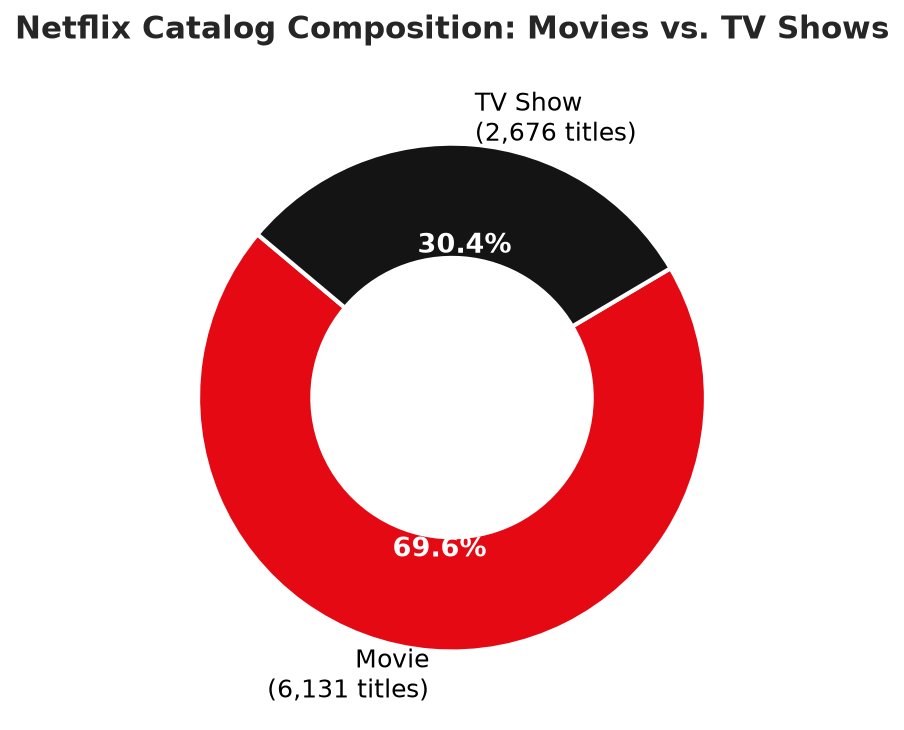

Saved: 01_content_type_distribution.png


In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
type_counts = df['type'].value_counts()
colors = [NETFLIX_RED, DARK_INK]

wedges, texts, autotexts = ax.pie(
    type_counts,
    labels=[f"{k}\n({v:,} titles)" for k, v in type_counts.items()],
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    textprops=dict(color='black', fontsize=12, fontweight='medium'),
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2)
)

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(13)
    autotext.set_fontweight('bold')

ax.set_title("Netflix Catalog Composition: Movies vs. TV Shows", fontsize=15, fontweight='bold', pad=20)
plt.tight_layout()
fig_path = FIGURES_DIR / '01_content_type_distribution.png'
plt.savefig(fig_path, dpi=200)
plt.show()
print(f"Saved: {fig_path.name}")

### 4.2 Yearly Catalog Additions by Content Type (2010–2021)

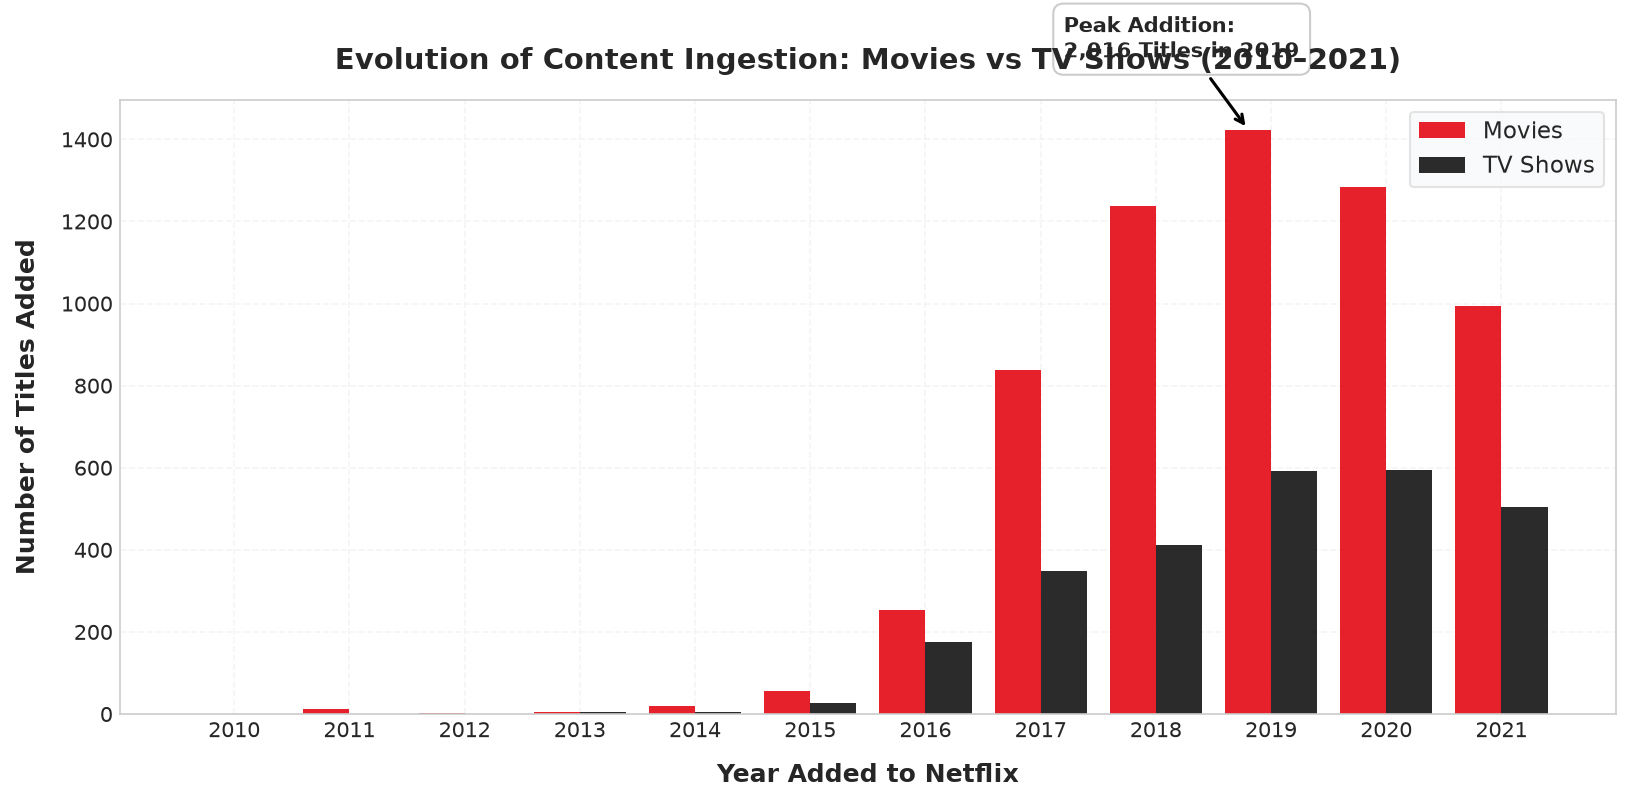

Saved: 02_yearly_growth_trend.png


In [5]:
# Filter to reliable years (2010 onwards)
yearly_df = df[df['year_added'] >= 2010].groupby(['year_added', 'type']).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(yearly_df.index))
width = 0.4

rects1 = ax.bar(x - width/2, yearly_df['Movie'], width, label='Movies', color=NETFLIX_RED, alpha=0.9, edgecolor='none')
rects2 = ax.bar(x + width/2, yearly_df['TV Show'], width, label='TV Shows', color=DARK_INK, alpha=0.9, edgecolor='none')

ax.set_xlabel('Year Added to Netflix', fontweight='bold', labelpad=10)
ax.set_ylabel('Number of Titles Added', fontweight='bold', labelpad=10)
ax.set_title('Evolution of Content Ingestion: Movies vs TV Shows (2010–2021)', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(yearly_df.index.astype(int))
ax.legend(frameon=True, facecolor=SOFT_BG, edgecolor='#ddd')

# Highlight peak in 2019
peak_year_idx = list(yearly_df.index.astype(int)).index(2019)
peak_total = yearly_df.loc[2019].sum()
ax.annotate(
    f'Peak Addition:\n2,016 Titles in 2019',
    xy=(peak_year_idx - width/2, yearly_df.loc[2019, 'Movie']),
    xytext=(peak_year_idx - 1.8, 1600),
    arrowprops=dict(facecolor=DARK_INK, arrowstyle='->', lw=1.5),
    fontweight='bold',
    fontsize=10,
    bbox=dict(boxstyle='round,pad=0.5', facecolor='#ffffff', edgecolor='#ccc')
)

plt.tight_layout()
fig_path = FIGURES_DIR / '02_yearly_growth_trend.png'
plt.savefig(fig_path, dpi=200)
plt.show()
print(f"Saved: {fig_path.name}")

### 4.3 Production Footprint: Top Countries and Format Divergence

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


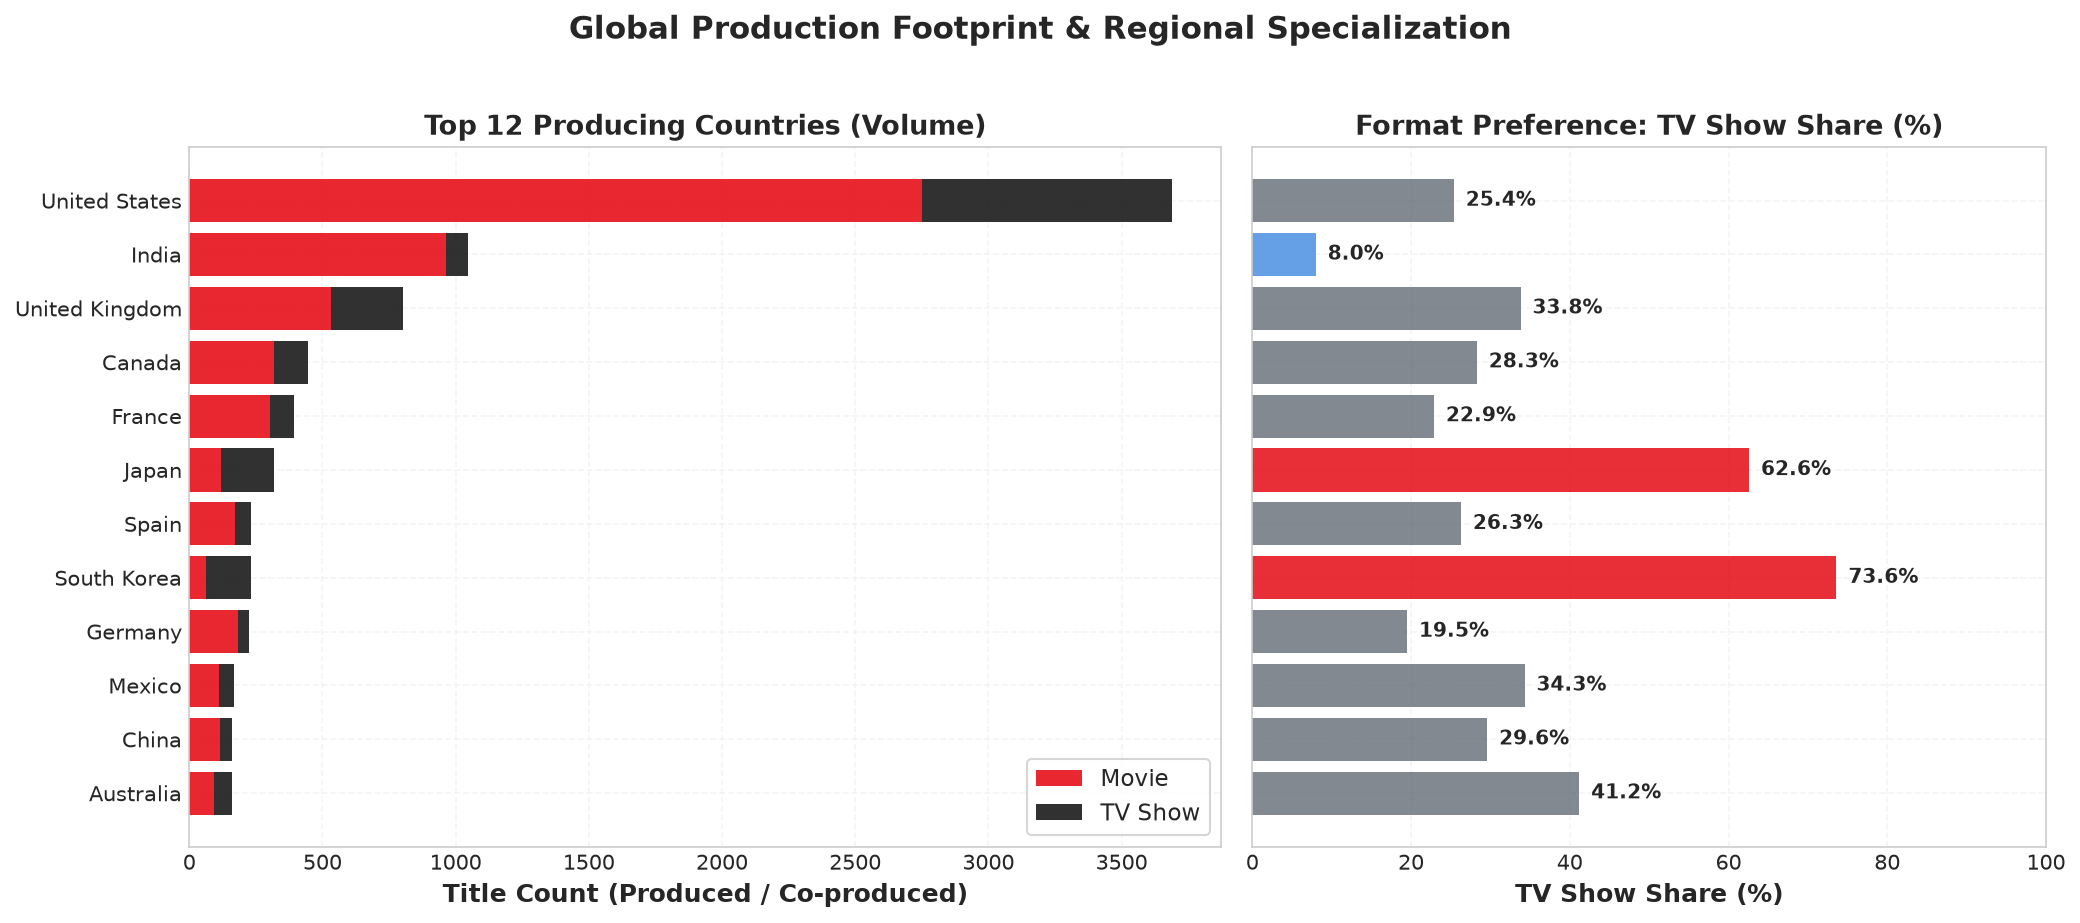

Saved: 03_top_countries_comparison.png


In [6]:
# Explode multi-country titles to credit each producing country
country_exploded = df.assign(country_clean=df['country'].dropna().str.split(', ')).explode('country_clean')
top_12_countries = country_exploded['country_clean'].value_counts().head(12).index

country_type_breakdown = country_exploded[country_exploded['country_clean'].isin(top_12_countries)].groupby(
    ['country_clean', 'type']
).size().unstack(fill_value=0)

country_type_breakdown['Total'] = country_type_breakdown.sum(axis=1)
country_type_breakdown['TV_Show_Pct'] = (country_type_breakdown['TV Show'] / country_type_breakdown['Total'] * 100).round(1)
country_type_breakdown = country_type_breakdown.sort_values(by='Total', ascending=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [1.3, 1]})

# Stacked bar of total volume
y_pos = np.arange(len(country_type_breakdown))
ax1.barh(y_pos, country_type_breakdown['Movie'], color=NETFLIX_RED, alpha=0.88, label='Movie')
ax1.barh(y_pos, country_type_breakdown['TV Show'], left=country_type_breakdown['Movie'], color=DARK_INK, alpha=0.88, label='TV Show')
ax1.set_yticks(y_pos)
ax1.set_yticklabels(country_type_breakdown.index, fontweight='medium')
ax1.set_xlabel('Title Count (Produced / Co-produced)', fontweight='bold')
ax1.set_title('Top 12 Producing Countries (Volume)', fontsize=13, fontweight='bold')
ax1.legend(loc='lower right', frameon=True)

# Percentage TV Show bar: highlighting South Korea and Japan vs India
bar_colors = [NETFLIX_RED if c in ['South Korea', 'Japan'] else '#4a90e2' if c == 'India' else MUTED_GRAY for c in country_type_breakdown.index]
ax2.barh(y_pos, country_type_breakdown['TV_Show_Pct'], color=bar_colors, alpha=0.85)
ax2.set_yticks(y_pos)
ax2.set_yticklabels(['' for _ in y_pos])
ax2.set_xlabel('TV Show Share (%)', fontweight='bold')
ax2.set_title('Format Preference: TV Show Share (%)', fontsize=13, fontweight='bold')
ax2.set_xlim(0, 100)

for i, pct in enumerate(country_type_breakdown['TV_Show_Pct']):
    ax2.text(pct + 1.5, i, f"{pct:.1f}%", va='center', fontsize=9.5, fontweight='bold')

plt.suptitle("Global Production Footprint & Regional Specialization", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
fig_path = FIGURES_DIR / '03_top_countries_comparison.png'
plt.savefig(fig_path, dpi=200, bbox_inches='tight')
plt.show()
print(f"Saved: {fig_path.name}")

### 4.4 Content Ratings & Audience Demographics

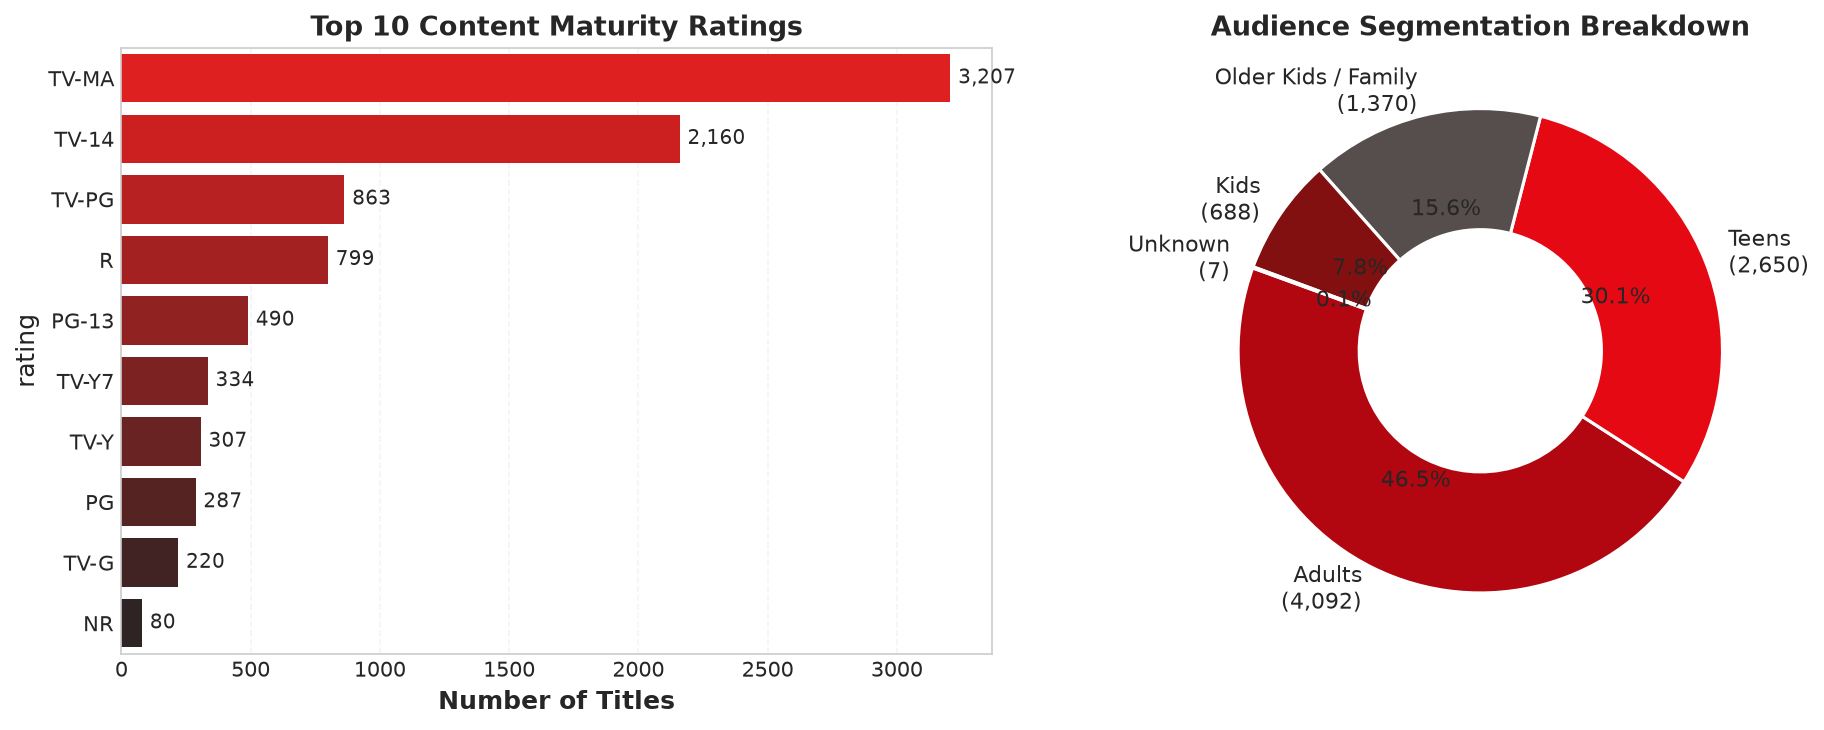

Saved: 04_content_ratings_distribution.png


In [7]:
# Rating distribution
top_ratings = df['rating'].value_counts().head(10)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Rating bar chart
sns.barplot(x=top_ratings.values, y=top_ratings.index, palette='dark:red_r', ax=ax1)
ax1.set_title("Top 10 Content Maturity Ratings", fontsize=13, fontweight='bold')
ax1.set_xlabel("Number of Titles", fontweight='bold')
for i, v in enumerate(top_ratings.values):
    ax1.text(v + 30, i, f"{v:,}", va='center', fontsize=9.5)

# Target Audience Grouping
aud_counts = df['target_audience'].value_counts()
aud_colors = ['#B20710', '#E50914', '#564d4d', '#831010', '#aaaaaa']
ax2.pie(
    aud_counts,
    labels=[f"{k}\n({v:,})" for k, v in aud_counts.items()],
    autopct='%1.1f%%',
    startangle=160,
    colors=aud_colors[:len(aud_counts)],
    wedgeprops=dict(width=0.5, edgecolor='white', linewidth=1.5),
    textprops=dict(fontsize=10.5)
)
ax2.set_title("Audience Segmentation Breakdown", fontsize=13, fontweight='bold')

plt.tight_layout()
fig_path = FIGURES_DIR / '04_content_ratings_distribution.png'
plt.savefig(fig_path, dpi=200)
plt.show()
print(f"Saved: {fig_path.name}")

### 4.5 Packaging Analysis: Movie Runtimes and TV Series Seasons

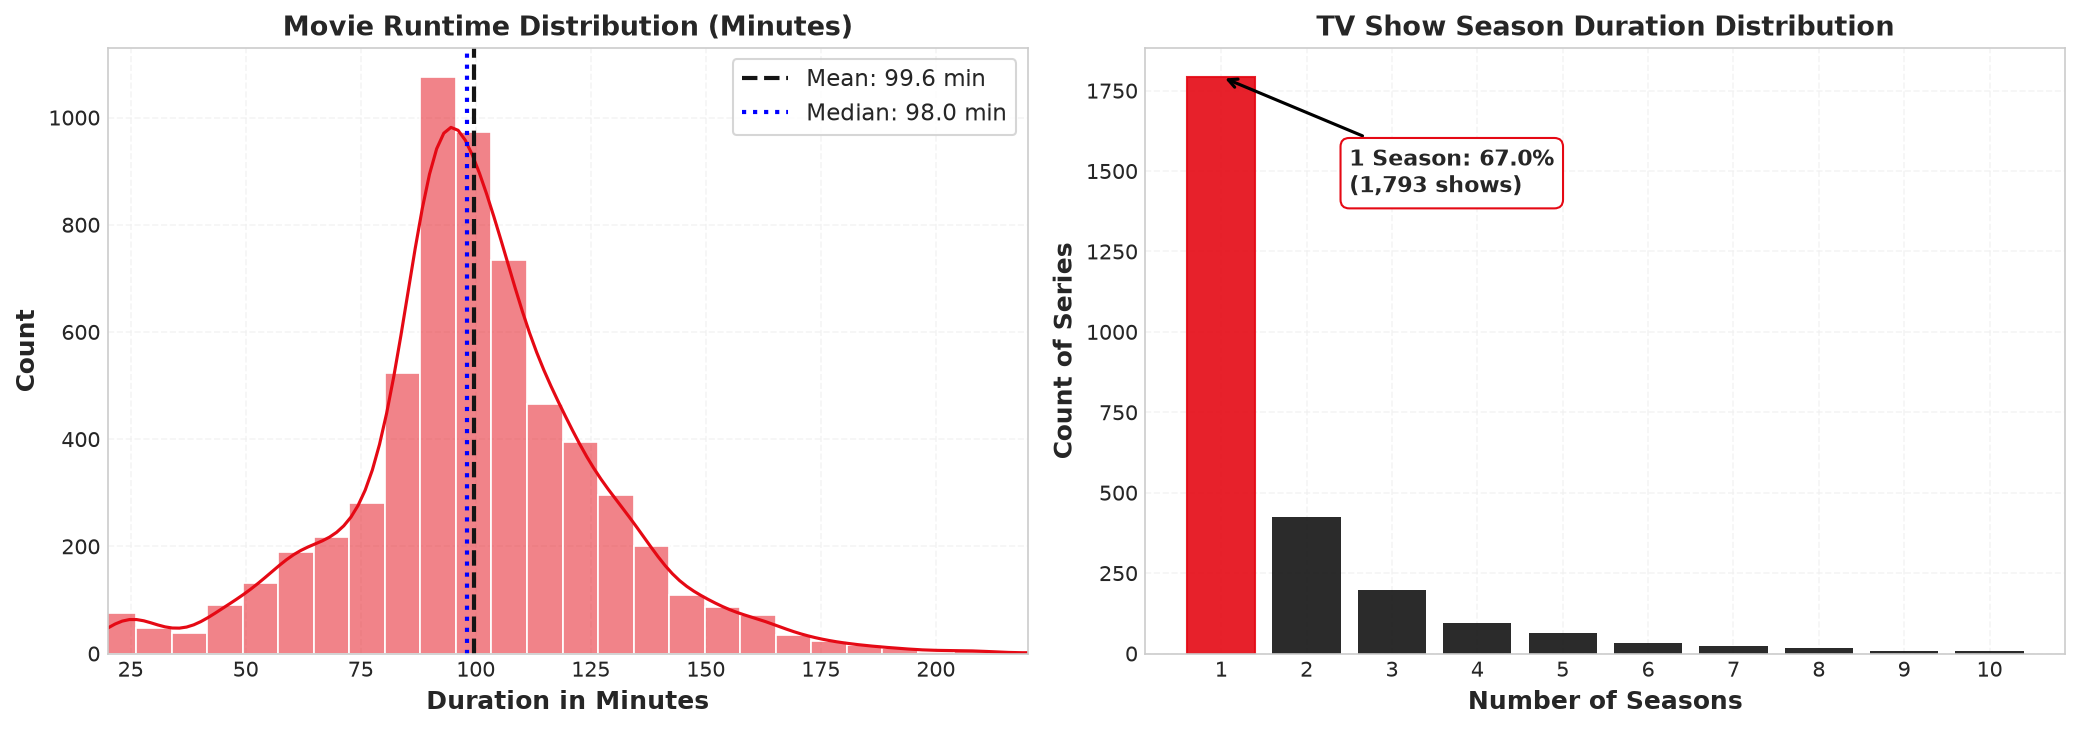

Saved: 05_movie_duration_distribution.png


In [8]:
movies = df[df['type'] == 'Movie'].copy()
tv_shows = df[df['type'] == 'TV Show'].copy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Movie Runtime Distribution
sns.histplot(movies['duration_num'].dropna(), bins=40, kde=True, color=NETFLIX_RED, ax=ax1, edgecolor='white')
mean_runtime = movies['duration_num'].mean()
median_runtime = movies['duration_num'].median()

ax1.axvline(mean_runtime, color=DARK_INK, linestyle='--', linewidth=2, label=f'Mean: {mean_runtime:.1f} min')
ax1.axvline(median_runtime, color='blue', linestyle=':', linewidth=2, label=f'Median: {median_runtime:.1f} min')
ax1.set_title("Movie Runtime Distribution (Minutes)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Duration in Minutes", fontweight='bold')
ax1.set_ylabel("Count", fontweight='bold')
ax1.set_xlim(20, 220)
ax1.legend(frameon=True)

# TV Show Seasons Count
season_counts = tv_shows['duration_num'].value_counts().sort_index().head(10)
bars = ax2.bar(season_counts.index.astype(int), season_counts.values, color=DARK_INK, alpha=0.9, edgecolor='none')
bars[0].set_color(NETFLIX_RED)  # Highlight 1 season
ax2.set_title("TV Show Season Duration Distribution", fontsize=13, fontweight='bold')
ax2.set_xlabel("Number of Seasons", fontweight='bold')
ax2.set_ylabel("Count of Series", fontweight='bold')
ax2.set_xticks(season_counts.index.astype(int))

# Annotate Season 1 proportion
s1_ratio = (tv_shows['duration_num'] == 1).sum() / len(tv_shows) * 100
ax2.annotate(
    f"1 Season: {s1_ratio:.1f}%\n({season_counts[1]:,} shows)",
    xy=(1, season_counts[1]),
    xytext=(2.5, season_counts[1] * 0.8),
    arrowprops=dict(facecolor=NETFLIX_RED, arrowstyle='->', lw=1.5),
    fontsize=10.5,
    fontweight='bold',
    bbox=dict(boxstyle='round,pad=0.4', facecolor='#fff', edgecolor=NETFLIX_RED)
)

plt.tight_layout()
fig_path = FIGURES_DIR / '05_movie_duration_distribution.png'
plt.savefig(fig_path, dpi=200)
plt.show()
print(f"Saved: {fig_path.name}")

### 4.6 Genre Landscape: Movies vs TV Shows

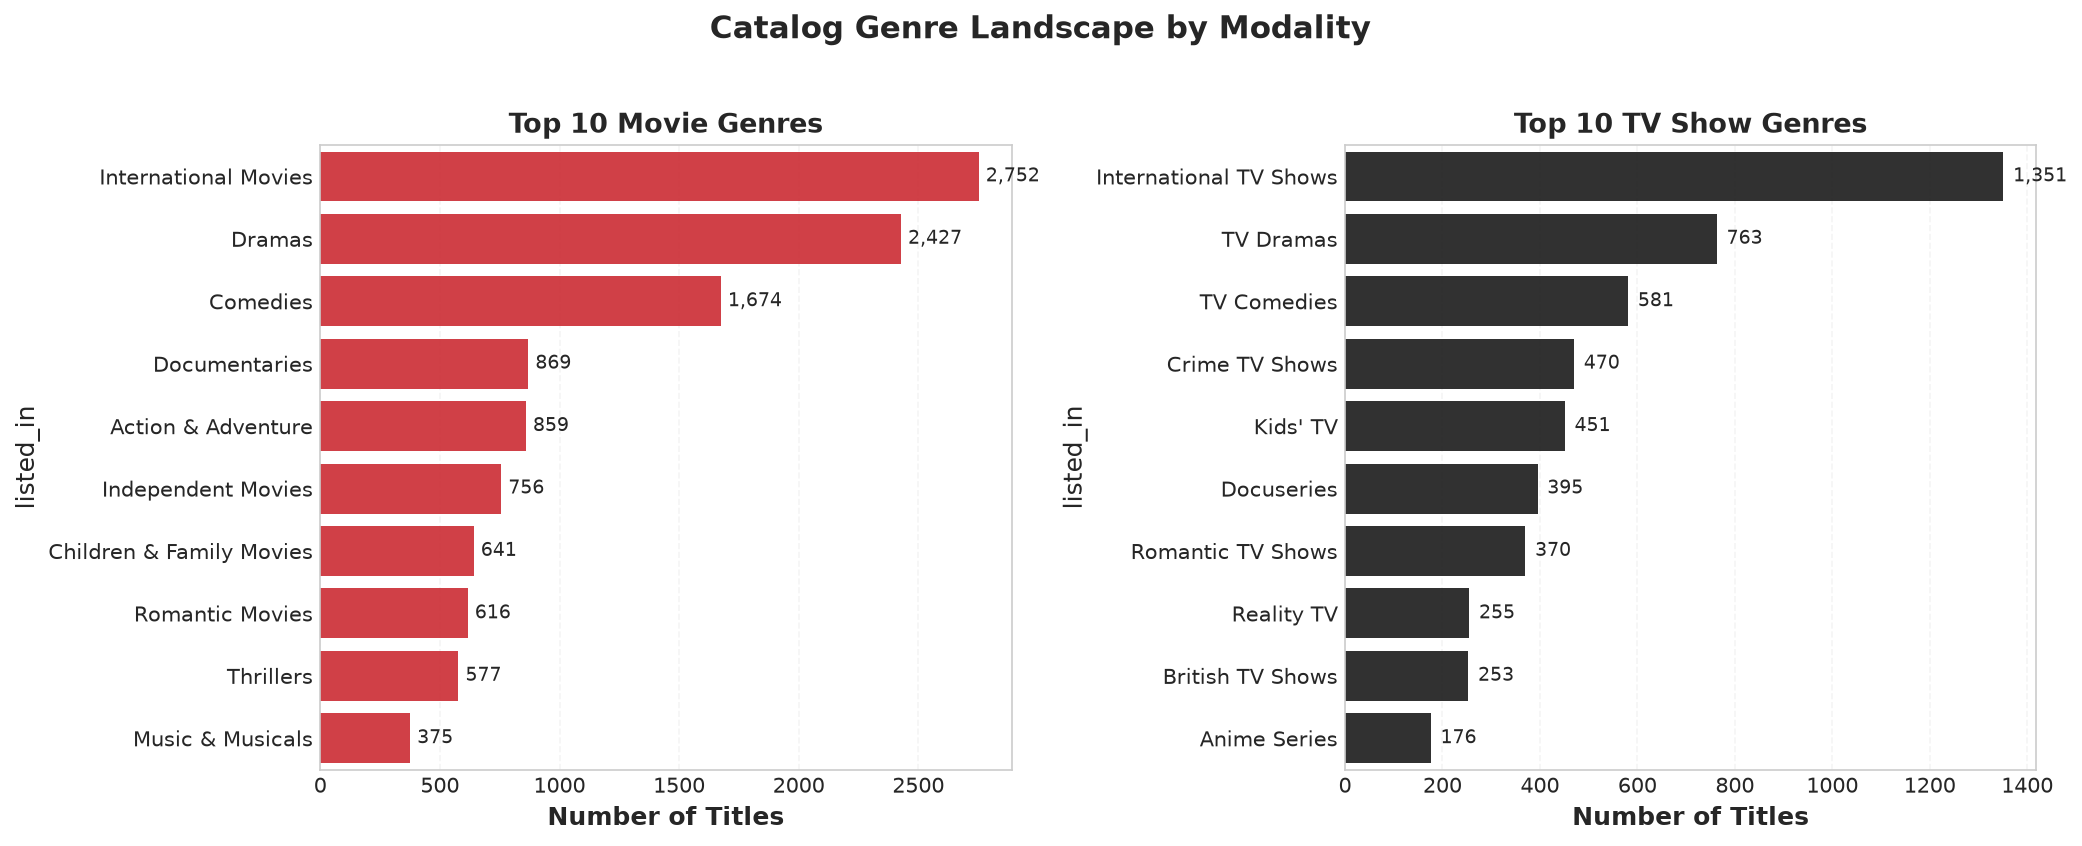

Saved: 07_top_genres_movies_tv.png


In [9]:
# Separate genres for Movies vs TV Shows
movie_genres = movies['listed_in'].str.split(', ').explode().value_counts().head(10)
tv_genres = tv_shows['listed_in'].str.split(', ').explode().value_counts().head(10)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

sns.barplot(x=movie_genres.values, y=movie_genres.index, ax=ax1, color=NETFLIX_RED, alpha=0.88)
ax1.set_title("Top 10 Movie Genres", fontsize=13, fontweight='bold')
ax1.set_xlabel("Number of Titles", fontweight='bold')
for i, v in enumerate(movie_genres.values):
    ax1.text(v + 30, i, f"{v:,}", va='center', fontsize=9)

sns.barplot(x=tv_genres.values, y=tv_genres.index, ax=ax2, color=DARK_INK, alpha=0.88)
ax2.set_title("Top 10 TV Show Genres", fontsize=13, fontweight='bold')
ax2.set_xlabel("Number of Titles", fontweight='bold')
for i, v in enumerate(tv_genres.values):
    ax2.text(v + 20, i, f"{v:,}", va='center', fontsize=9)

plt.suptitle("Catalog Genre Landscape by Modality", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
fig_path = FIGURES_DIR / '07_top_genres_movies_tv.png'
plt.savefig(fig_path, dpi=200, bbox_inches='tight')
plt.show()
print(f"Saved: {fig_path.name}")

### 4.7 Content Age & Ingestion Lag (Original vs Legacy Catalog)

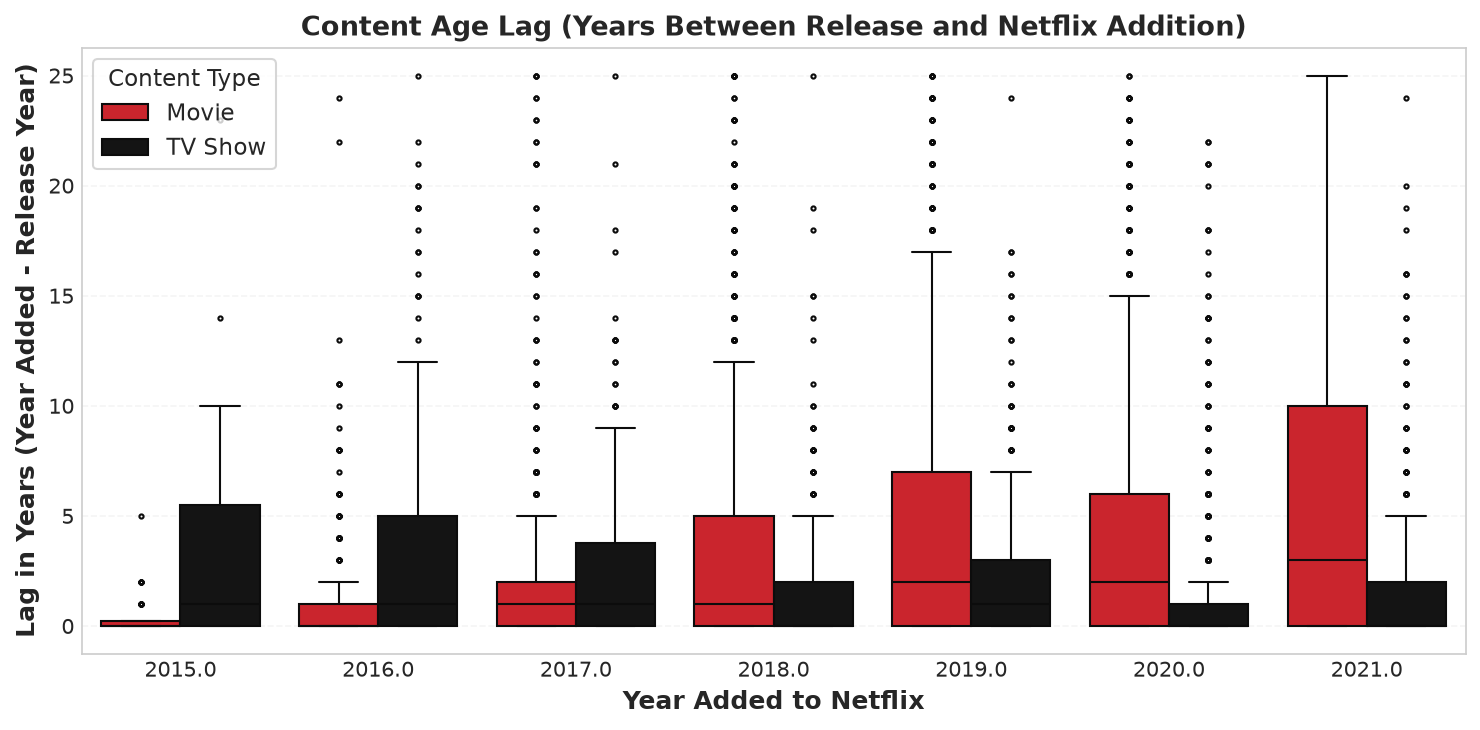

Saved: 08_release_to_addition_lag.png


In [10]:
valid_lag = df[(df['addition_lag_years'] >= 0) & (df['addition_lag_years'] <= 25) & (df['year_added'] >= 2015)].copy()

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(x='year_added', y='addition_lag_years', hue='type', data=valid_lag, palette=[NETFLIX_RED, DARK_INK], ax=ax, fliersize=2)

ax.set_title("Content Age Lag (Years Between Release and Netflix Addition)", fontsize=13, fontweight='bold')
ax.set_xlabel("Year Added to Netflix", fontweight='bold')
ax.set_ylabel("Lag in Years (Year Added - Release Year)", fontweight='bold')
ax.legend(title='Content Type', frameon=True)

plt.tight_layout()
fig_path = FIGURES_DIR / '08_release_to_addition_lag.png'
plt.savefig(fig_path, dpi=200)
plt.show()
print(f"Saved: {fig_path.name}")

### 4.8 Regional Spotlight: The Phenomenon of Korean Content (K-Drama)

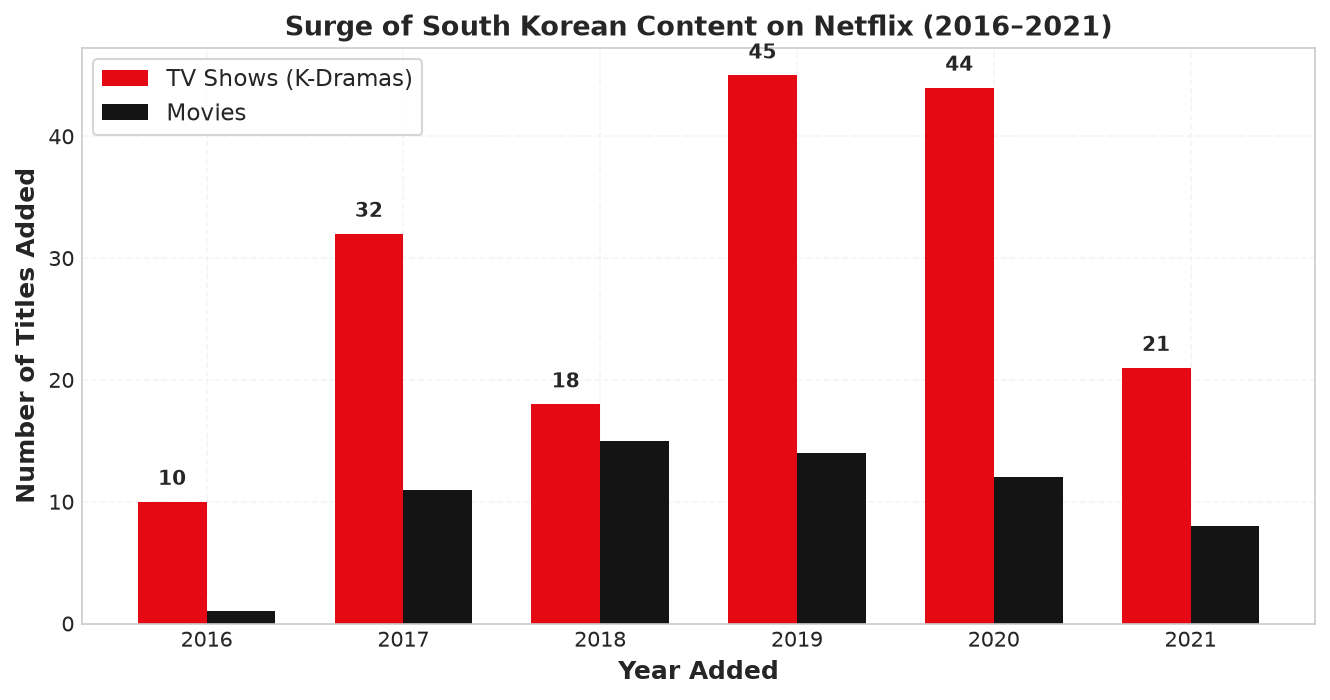

Saved: 09_korea_content_growth.png


In [11]:
korea_df = df[df['country'].str.contains('South Korea', na=False)].copy()
korea_yearly = korea_df[korea_df['year_added'] >= 2016].groupby(['year_added', 'type']).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(9, 4.8))
years = korea_yearly.index.astype(int)
width = 0.35

ax.bar(years - width/2, korea_yearly['TV Show'], width, label='TV Shows (K-Dramas)', color=NETFLIX_RED)
ax.bar(years + width/2, korea_yearly.get('Movie', pd.Series(0, index=korea_yearly.index)), width, label='Movies', color=DARK_INK)

ax.set_title("Surge of South Korean Content on Netflix (2016–2021)", fontsize=13, fontweight='bold')
ax.set_xlabel("Year Added", fontweight='bold')
ax.set_ylabel("Number of Titles Added", fontweight='bold')
ax.set_xticks(years)
ax.legend(frameon=True)

for i, y in enumerate(years):
    tv_cnt = korea_yearly.loc[y, 'TV Show']
    ax.text(y - width/2, tv_cnt + 1, str(tv_cnt), ha='center', va='bottom', fontsize=9.5, fontweight='bold')

plt.tight_layout()
fig_path = FIGURES_DIR / '09_korea_content_growth.png'
plt.savefig(fig_path, dpi=200)
plt.show()
print(f"Saved: {fig_path.name}")

## 5. Text Mining: Synopsis (Description) Analysis

In [12]:
# TF-IDF analysis on descriptions by genre
sample_genres = ['Documentaries', 'Comedies', 'Dramas', 'Horror Movies', 'Action & Adventure']
genre_keywords = {}

for g in sample_genres:
    subset = df[df['listed_in'].str.contains(g, na=False)]['description'].dropna()
    tfidf = TfidfVectorizer(stop_words='english', max_features=10, ngram_range=(1, 2))
    matrix = tfidf.fit_transform(subset)
    words = tfidf.get_feature_names_out()
    scores = np.asarray(matrix.mean(axis=0)).ravel()
    top_words = sorted(list(zip(words, scores)), key=lambda x: x[1], reverse=True)[:5]
    genre_keywords[g] = [w[0] for w in top_words]

print("=== Key Salient Terms by Genre (TF-IDF) ===")
for g, kws in genre_keywords.items():
    print(f"{g:20s}: {', '.join(kws)}")

=== Key Salient Terms by Genre (TF-IDF) ===
Documentaries       : documentary, life, world, film, family
Comedies            : new, life, family, friends, man
Dramas              : young, life, family, love, man
Horror Movies       : young, home, group, woman, new
Action & Adventure  : young, man, life, world, new


## 6. Machine Learning Application 1: Content-Based Recommendation Engine

We construct a recommendation engine by vectorizing metadata fields:  
`'title' + 'director' + 'cast' + 'listed_in' + 'description'`  
using TF-IDF with sublinear term-frequency scaling and calculating pairwise Cosine Similarity.

In [13]:
# Prepare metadata soup for recommendation
def create_soup(row):
    return f"{row['title']} {row['director_clean']} {row['cast_clean']} {row['listed_in']} {row['description']}"

df['soup'] = df.apply(create_soup, axis=1)

tfidf_rec = TfidfVectorizer(stop_words='english', min_df=2, max_features=10000)
tfidf_matrix = tfidf_rec.fit_transform(df['soup'])

# Precompute index map
indices = pd.Series(df.index, index=df['title'].str.lower()).drop_duplicates()

def recommend_titles(title, top_k=5):
    title_key = title.strip().lower()
    if title_key not in indices:
        # Fallback to fuzzy substring match
        matches = [t for t in indices.index if title_key in t]
        if not matches:
            return f"Title '{title}' not found in catalog."
        title_key = matches[0]
    
    idx = indices[title_key]
    sim_scores = cosine_similarity(tfidf_matrix[idx], tfidf_matrix).flatten()
    top_indices = sim_scores.argsort()[-(top_k+1):-1][::-1]
    
    results = []
    for rank, i in enumerate(top_indices, 1):
        results.append({
            'Rank': rank,
            'Title': df.iloc[i]['title'],
            'Type': df.iloc[i]['type'],
            'Rating': df.iloc[i]['rating'],
            'Genres': df.iloc[i]['listed_in'],
            'Similarity': round(float(sim_scores[i]), 3)
        })
    return pd.DataFrame(results)

# Test recommendations
test_titles = ['Stranger Things', 'Squid Game', 'Inception', 'Breaking Bad']
for t in test_titles:
    if any(df['title'].str.lower() == t.lower()):
        print(f"\n--- Recommendations for '{t}' ---")
        print(recommend_titles(t, top_k=3))


--- Recommendations for 'Stranger Things' ---
   Rank                   Title     Type Rating  \
0     1  Beyond Stranger Things  TV Show  TV-14   
1     2              Good Witch  TV Show  TV-PG   
2     3               Homefront    Movie      R   

                                              Genres  Similarity  
0  Stand-Up Comedy & Talk Shows, TV Mysteries, TV...       0.547  
1                     TV Dramas, TV Sci-Fi & Fantasy       0.141  
2                                 Action & Adventure       0.136  

--- Recommendations for 'Squid Game' ---
   Rank                            Title     Type Rating  \
0     1                  Prison Playbook  TV Show  TV-MA   
1     2  Love (ft. Marriage and Divorce)  TV Show  TV-14   
2     3                Hospital Playlist  TV Show  TV-14   

                                              Genres  Similarity  
0  International TV Shows, Korean TV Shows, TV Co...       0.351  
1                  International TV Shows, TV Dramas       0.33

## 7. Machine Learning Application 2: Content Format Classification

Can metadata features (runtime excluded, to prevent trivial leakage) predict whether a title is a  
**Movie (0)** or **TV Show (1)** based purely on genres, target audience, release year, country origin, and synopsis length?

In [14]:
# Feature engineering for classification without data leakage
ml_df = df.copy()

# Binary target: 1 if TV Show, 0 if Movie
ml_df['target_is_tv'] = (ml_df['type'] == 'TV Show').astype(int)

# Length and presence features
ml_df['desc_char_len'] = ml_df['description'].str.len().fillna(0).astype(float)
ml_df['desc_word_count'] = ml_df['description'].apply(lambda x: len(str(x).split())).astype(float)
ml_df['cast_count'] = ml_df['cast'].apply(lambda x: len(str(x).split(',')) if pd.notna(x) else 0).astype(float)
ml_df['has_director'] = ml_df['director'].notnull().astype(int)

ml_features = ['release_year', 'addition_lag_years', 'desc_char_len', 'desc_word_count', 'cast_count', 'has_director']

# Extract top genres as dummy flags
top_genres_list = df['listed_in'].str.split(', ').explode().value_counts().head(25).index.tolist()
for g in top_genres_list:
    col_name = f"feat_genre_{re.sub(r'[^a-zA-Z0-9]', '_', g)}"
    ml_df[col_name] = ml_df['listed_in'].str.contains(g, na=False, regex=False).astype(int)
    ml_features.append(col_name)

# Extract top countries
top_countries_list = df['primary_country'].value_counts().head(10).index.tolist()
for c in top_countries_list:
    col_name = f"feat_country_{re.sub(r'[^a-zA-Z0-9]', '_', c)}"
    ml_df[col_name] = (ml_df['primary_country'] == c).astype(int)
    ml_features.append(col_name)

# Dummy variables for audience
audience_dummies = pd.get_dummies(ml_df['target_audience'], prefix='feat_aud', drop_first=True, dtype=int)
ml_df = pd.concat([ml_df, audience_dummies], axis=1)
ml_features.extend(audience_dummies.columns.tolist())

feature_cols = ml_features

# Impute any missing addition_lag_years with median
ml_df['addition_lag_years'] = ml_df['addition_lag_years'].fillna(ml_df['addition_lag_years'].median()).astype(float)

X = ml_df[feature_cols].astype(float)
y = ml_df['target_is_tv']

print(f"Features matrix shape: {X.shape}")
print(f"Target distribution: TV Show = {y.sum()} ({y.mean()*100:.1f}%), Movie = {(1-y).sum()} ({(1-y.mean())*100:.1f}%)")

Features matrix shape: (8807, 45)
Target distribution: TV Show = 2676 (30.4%), Movie = 6131 (69.6%)


### 7.1 Cross-Validation & Test Set Evaluation

In [15]:
# Stratified Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1)
}

cv_results = {}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    fold_aucs = []
    for train_idx, val_idx in skf.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
        model.fit(X_tr, y_tr)
        probs = model.predict_proba(X_val)[:, 1]
        fold_aucs.append(roc_auc_score(y_val, probs))
    cv_results[name] = np.mean(fold_aucs)
    print(f"5-Fold CV ROC-AUC [{name}]: {np.mean(fold_aucs):.4f} (+/- {np.std(fold_aucs):.4f})")

# Fit best model (Random Forest) on full training set
best_model = models['Random Forest']
best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

eval_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_prob)
}

print("\n=== Hold-out Test Set Performance (Random Forest) ===")
for k, v in eval_metrics.items():
    print(f"{k:12s}: {v:.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=['Movie', 'TV Show']))

5-Fold CV ROC-AUC [Logistic Regression]: 0.9997 (+/- 0.0001)


5-Fold CV ROC-AUC [Random Forest]: 0.9996 (+/- 0.0002)



=== Hold-out Test Set Performance (Random Forest) ===
Accuracy    : 0.9938
Precision   : 0.9870
Recall      : 0.9925
F1-Score    : 0.9897
ROC-AUC     : 0.9993

Classification Report:
               precision    recall  f1-score   support

       Movie       1.00      0.99      1.00      1227
     TV Show       0.99      0.99      0.99       535

    accuracy                           0.99      1762
   macro avg       0.99      0.99      0.99      1762
weighted avg       0.99      0.99      0.99      1762



### 7.2 Feature Importance

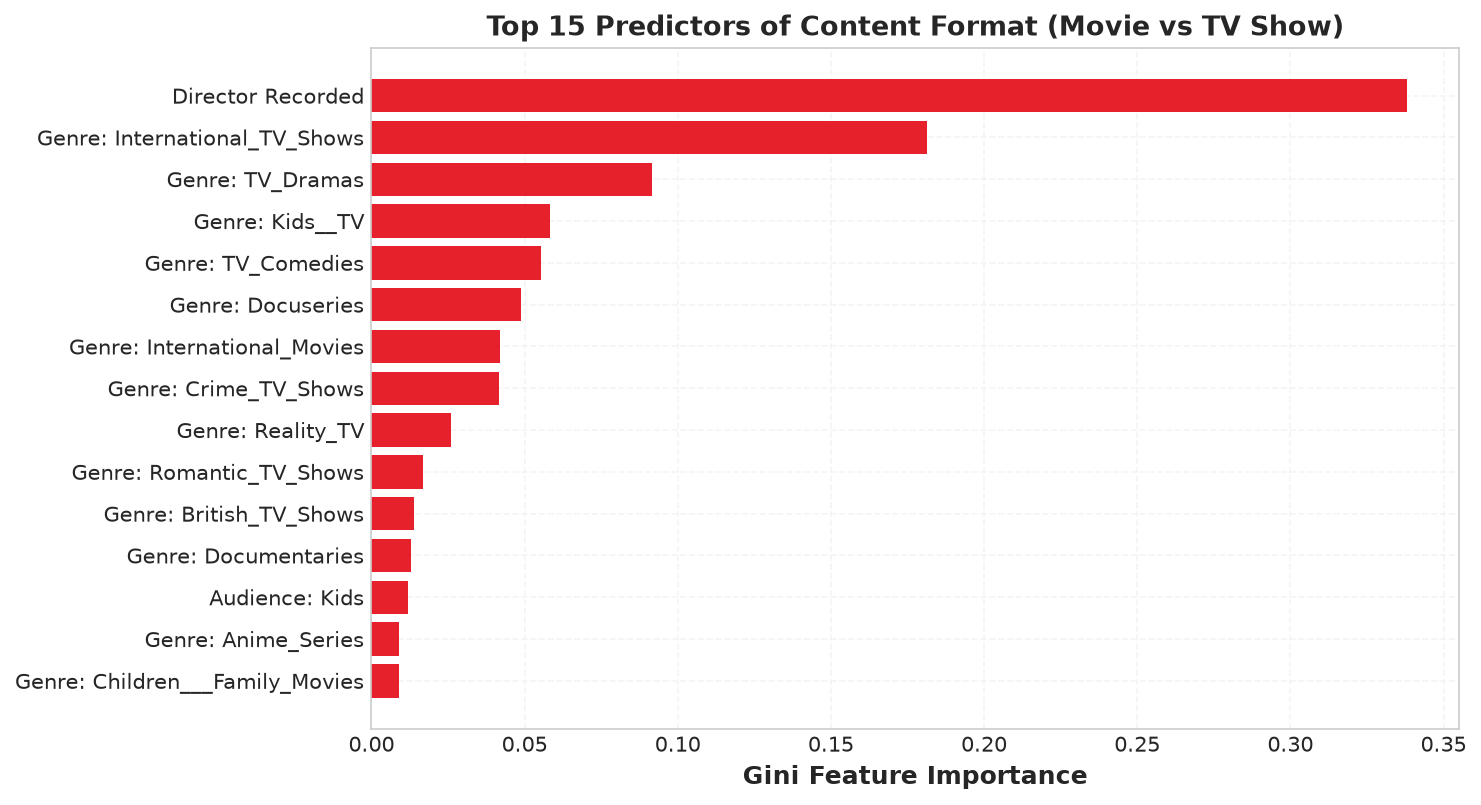

Saved: 11_ml_feature_importance.png


In [16]:
importances = best_model.feature_importances_
top_idx = importances.argsort()[-15:][::-1]
top_features = [feature_cols[i] for i in top_idx]
top_importances = importances[top_idx]

fig, ax = plt.subplots(figsize=(10, 5.5))
clean_names = [
    f.replace('feat_genre_', 'Genre: ')
     .replace('feat_country_', 'Country: ')
     .replace('feat_aud_', 'Audience: ')
     .replace('has_director', 'Director Recorded')
     .replace('addition_lag_years', 'Catalog Addition Lag')
     .replace('desc_char_len', 'Description Length')
     .replace('desc_word_count', 'Word Count')
     .replace('cast_count', 'Cast Member Count')
    for f in top_features
]

ax.barh(range(len(top_features))[::-1], top_importances, color=NETFLIX_RED, alpha=0.9, edgecolor='none')
ax.set_yticks(range(len(top_features))[::-1])
ax.set_yticklabels(clean_names, fontweight='medium')
ax.set_xlabel('Gini Feature Importance', fontweight='bold')
ax.set_title('Top 15 Predictors of Content Format (Movie vs TV Show)', fontsize=13, fontweight='bold')

plt.tight_layout()
fig_path = FIGURES_DIR / '11_ml_feature_importance.png'
plt.savefig(fig_path, dpi=200)
plt.show()
print(f"Saved: {fig_path.name}")

## 8. Export Data & Results for Web Dashboard

In [17]:
# 1. Summary Metrics JSON
summary_stats = {
    'total_titles': int(len(df)),
    'movies_count': int((df['type'] == 'Movie').sum()),
    'tv_shows_count': int((df['type'] == 'TV Show').sum()),
    'movies_pct': round(float((df['type'] == 'Movie').mean() * 100), 1),
    'tv_shows_pct': round(float((df['type'] == 'TV Show').mean() * 100), 1),
    'unique_countries': int(df['primary_country'].nunique()),
    'avg_movie_duration_min': round(float(movies['duration_num'].mean()), 1),
    'median_movie_duration_min': round(float(movies['duration_num'].median()), 1),
    'tv_one_season_pct': round(float((tv_shows['duration_num'] == 1).mean() * 100), 1),
    'top_rating': str(df['rating'].value_counts().index[0]),
    'top_rating_pct': round(float(df['rating'].value_counts().iloc[0] / len(df) * 100), 1),
    'ml_accuracy': round(float(eval_metrics['Accuracy']), 3),
    'ml_roc_auc': round(float(eval_metrics['ROC-AUC']), 3),
    'yearly_trend': {
        'years': [int(y) for y in yearly_df.index],
        'movies': [int(m) for m in yearly_df['Movie']],
        'tv_shows': [int(s) for s in yearly_df['TV Show']]
    },
    'top_countries': {
        'labels': [str(c) for c in country_type_breakdown.index],
        'movies': [int(m) for m in country_type_breakdown['Movie']],
        'tv_shows': [int(s) for s in country_type_breakdown['TV Show']]
    },
    'top_ratings': {
        'labels': [str(r) for r in top_ratings.index],
        'counts': [int(c) for c in top_ratings.values]
    },
    'top_genres': {
        'movie_genres': [{'name': str(k), 'count': int(v)} for k, v in movie_genres.items()],
        'tv_genres': [{'name': str(k), 'count': int(v)} for k, v in tv_genres.items()]
    }
}

with open(BASE_DIR / 'results.json', 'w', encoding='utf-8') as f:
    json.dump(summary_stats, f, indent=2, ensure_ascii=False)

# Export for web dashboard
with open(DASHBOARD_DATA_DIR / 'results.js', 'w', encoding='utf-8') as f:
    f.write(f"window.NETFLIX_STATS = {json.dumps(summary_stats, indent=2, ensure_ascii=False)};\n")

# 2. Export Light-weight Catalog for the Interactive Web Database Browser
catalog_records = []
for _, row in df.iterrows():
    catalog_records.append({
        'id': str(row['show_id']),
        'type': str(row['type']),
        'title': str(row['title']),
        'director': str(row['director']) if pd.notna(row['director']) else '',
        'cast': str(row['cast']) if pd.notna(row['cast']) else '',
        'country': str(row['country']) if pd.notna(row['country']) else '',
        'date_added': str(row['date_added']).strip() if pd.notna(row['date_added']) else '',
        'year_added': int(row['year_added']) if pd.notna(row['year_added']) else None,
        'release_year': int(row['release_year']),
        'rating': str(row['rating']) if pd.notna(row['rating']) else 'Unknown',
        'duration': str(row['duration']) if pd.notna(row['duration']) else '',
        'genres': str(row['listed_in']),
        'desc': str(row['description'])
    })

catalog_json_path = DASHBOARD_DATA_DIR / 'netflix_catalog.json'
with open(catalog_json_path, 'w', encoding='utf-8') as f:
    json.dump(catalog_records, f, ensure_ascii=False)

print(f"Exported summary stats to {BASE_DIR / 'results.json'} and {DASHBOARD_DATA_DIR / 'results.js'}")
print(f"Exported {len(catalog_records):,} catalog records to {catalog_json_path}")

Exported summary stats to /Users/sky/orca/projects/10.16/analysis/results.json and /Users/sky/orca/projects/10.16/dashboard/data/results.js
Exported 8,807 catalog records to /Users/sky/orca/projects/10.16/dashboard/data/netflix_catalog.json
